# OilyGiant: Prospección y Viabilidad de Nuevos Yacimientos

**Diseño de Modelo Predictivo para Maximización de Beneficios**

Durante casi una década he aprendido que un proyecto exitoso no empieza
en la construcción, sino en un riguroso análisis topográfico y
estructural. Un mal cálculo en los cimientos compromete toda la obra.
Hoy, en lugar de planos y concreto, nuestra topografía son los datos
geológicos, y nuestros cimientos, la regresión lineal.

En este cuaderno, estructuraremos un modelo predictivo para la compañía
**OilyGiant**. El objetivo es evaluar tres regiones distintas, proyectar
el volumen de reservas en nuevos pozos petrolíferos y, mediante
simulaciones de riesgo (Bootstrapping), determinar la región que ofrezca
el mayor margen de beneficio y la máxima estabilidad financiera (riesgo
de pérdida inferior al 2.5%).

La presentación está estructurada para ser visualmente clara, modular y
escalable.

In [1]:
# Levantamiento inicial: Importación de librerías esenciales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Configuración visual (El toque de diseño para una presentación ejecutiva)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    'figure.figsize': (12, 6),
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold'
})

# Fijar semilla para reproducibilidad de nuestro "estudio de suelo"
RANDOM_STATE = 42

## 1. Exploración del Terreno (Preparación de Datos)

Cargaremos los estudios geológicos de las tres regiones. Descartaremos
la columna `id`, ya que funciona como una etiqueta nominativa y no
aporta valor estructural a nuestro modelo predictivo.

In [2]:
# Carga de los archivos CSV
df_0 = pd.read_csv('/datasets/geo_data_0.csv')
df_1 = pd.read_csv('/datasets/geo_data_1.csv')
df_2 = pd.read_csv('/datasets/geo_data_2.csv')

# Eliminación de la columna 'id' para evitar ruido en el entrenamiento
df_0 = df_0.drop('id', axis=1)
df_1 = df_1.drop('id', axis=1)
df_2 = df_2.drop('id', axis=1)

print("Muestra estructural de la Región 0:")
display(df_0.head(3))

Muestra estructural de la Región 0:

## 2. Planos Estructurales: Entrenamiento y Validación del Modelo

Siguiendo las restricciones del proyecto, utilizaremos exclusivamente
**Regresión Lineal**. Para evitar la duplicidad de código —un principio
básico tanto en el diseño paramétrico como en la programación—
encapsularemos el proceso en una función que divida los datos (75:25),
entrene el modelo y nos devuelva las predicciones y el error cuadrático
medio (RMSE). El RMSE será nuestro “margen de tolerancia”.

In [3]:
def train_and_evaluate(df, region_name):
    """
    Divide los datos, entrena un modelo de regresión lineal y evalúa el desempeño.
    """
    X = df.drop('product', axis=1)
    y = df['product']
    
    X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)
    
    # Construcción del modelo
    model = LinearRegression()
    model.fit(X_train, y_train)
    
    # Proyección
    preds = model.predict(X_valid)
    preds = pd.Series(preds, index=y_valid.index) # Alinear índices con las respuestas correctas
    
    # Métricas de validación
    mean_reserve = preds.mean()
    rmse = np.sqrt(mean_squared_error(y_valid, preds))
    
    print(f"--- {region_name} ---")
    print(f"Volumen medio predicho: {mean_reserve:.2f} miles de barriles")
    print(f"RMSE (Margen de error): {rmse:.2f}\n")
    
    return preds, y_valid

# Ejecución paramétrica para las tres regiones
preds_0, valid_0 = train_and_evaluate(df_0, "Región 0")
preds_1, valid_1 = train_and_evaluate(df_1, "Región 1")
preds_2, valid_2 = train_and_evaluate(df_2, "Región 2")

--- Región 0 ---
Volumen medio predicho: 92.40 miles de barriles
RMSE (Margen de error): 37.76

--- Región 1 ---
Volumen medio predicho: 68.71 miles de barriles
RMSE (Margen de error): 0.89

--- Región 2 ---
Volumen medio predicho: 94.77 miles de barriles
RMSE (Margen de error): 40.15


**Análisis del Modelo:** \* La **Región 1** presenta un RMSE
sorprendentemente bajo (casi 0), lo que indica una correlación lineal
casi perfecta entre sus características ocultas y el volumen de
reservas. \* Las **Regiones 0 y 2** tienen volúmenes medios predichos
más altos, pero su margen de error (RMSE de ~37-40) sugiere una
dispersión considerable. Es aquí donde la evaluación de riesgos
determinará si el volumen compensa la incertidumbre.

## 3. Presupuesto y Viabilidad del Proyecto

Antes de seleccionar pozos, debemos calcular el punto de equilibrio
financiero (Break-even). Si el terreno no produce lo mínimo
indispensable, el proyecto no es viable.

In [4]:
# Constantes del proyecto (Nuestro presupuesto de obra)
BUDGET = 100_000_000         # Presupuesto total en USD
TOTAL_WELLS = 200            # Pozos a desarrollar
REVENUE_PER_UNIT = 4500      # Ingreso por unidad (1,000 barriles)
MAX_RISK = 0.025             # Umbral de riesgo de pérdida (2.5%)

# Cálculo del volumen mínimo para evitar pérdidas
# Costo por pozo = BUDGET / TOTAL_WELLS
cost_per_well = BUDGET / TOTAL_WELLS
breakeven_volume = cost_per_well / REVENUE_PER_UNIT

print(f"Inversión por pozo: ${cost_per_well:,.2f} USD")
print(f"Punto de equilibrio (Break-even): {breakeven_volume:.2f} miles de barriles por pozo")

Inversión por pozo: $500,000.00 USD
Punto de equilibrio (Break-even): 111.11 miles de barriles por pozo

**Conclusión de Viabilidad:** El punto de equilibrio es de **111.11
miles de barriles** por pozo. Si revisamos los volúmenes medios
predichos en el Paso 2 (Región 0: ~92.59, Región 1: ~68.73, Región 2:
~94.97), notamos que **ninguna región tiene un volumen medio que supere
el punto de equilibrio**. Esto significa que no podemos perforar al
azar. Debemos aplicar una estrategia selectiva: explorar 500 puntos y
seleccionar estrictamente los 200 con las estimaciones más altas.

## 4. Proyección de Rendimientos (Ganancia Potencial)

Diseñaremos una función que seleccione los mejores 200 pozos basados en
nuestras predicciones y calcule el beneficio bruto real que estos pozos
generarían utilizando sus valores objetivo (respuestas correctas).

In [5]:
def calculate_profit(predictions, target, count=TOTAL_WELLS):
    """
    Selecciona los mejores pozos según las predicciones y calcula el beneficio total 
    usando los volúmenes reales.
    """
    # Ordenar predicciones de mayor a menor
    preds_sorted = predictions.sort_values(ascending=False)
    
    # Seleccionar los objetivos (targets) correspondientes a los 200 mejores índices
    selected_targets = target.loc[preds_sorted.index][:count]
    
    # Calcular ingresos brutos y restar presupuesto
    total_revenue = selected_targets.sum() * REVENUE_PER_UNIT
    profit = total_revenue - BUDGET
    
    return profit

profit_0 = calculate_profit(preds_0, valid_0)
profit_1 = calculate_profit(preds_1, valid_1)
profit_2 = calculate_profit(preds_2, valid_2)

print(f"Beneficio potencial Top 200 Región 0: ${profit_0:,.2f} USD")
print(f"Beneficio potencial Top 200 Región 1: ${profit_1:,.2f} USD")
print(f"Beneficio potencial Top 200 Región 2: ${profit_2:,.2f} USD")

Beneficio potencial Top 200 Región 0: $33,591,411.14 USD
Beneficio potencial Top 200 Región 1: $24,150,866.97 USD
Beneficio potencial Top 200 Región 2: $25,985,717.59 USD

**Análisis Preliminar:** Bajo condiciones ideales (escogiendo
exactamente los 200 mejores de toda la región), todas las zonas son
rentables. Sin embargo, en el campo real, las máquinas solo explorarán
**500 puntos aleatorios** a la vez. Necesitamos simular esta realidad
mediante Bootstrapping para medir el verdadero riesgo operativo.

## 5. Análisis de Riesgos y Cimentación (Bootstrapping)

Emplearemos la técnica de Bootstrapping para crear 1,000 submuestras
aleatorias de 500 pozos. De cada submuestra, seleccionaremos los mejores
200 y calcularemos su beneficio. Esto nos dará una distribución de
probabilidad clara y un intervalo de confianza del 95%.

In [6]:
# Semilla aleatoria para garantizar la reproducibilidad de las 1,000 iteraciones
state = np.random.RandomState(12345)

def evaluate_risk_and_profit(target, predictions, count=200, sample_size=500):
    values = []

    for i in range(1000):
        # 1. Muestreo aleatorio de 500 pozos explorados (con reemplazo)
        target_subsample = target.sample(n=sample_size, replace=True, random_state=state)
        
        # 2. Alineamos las predicciones con los índices de la muestra seleccionada
        probs_subsample = predictions[target_subsample.index]
        
        # 3. Calculamos la ganancia de los 200 mejores pozos de esta submuestra
        profit = calculate_profit(probs_subsample, target_subsample, count)
        values.append(profit)

    # Convertimos los resultados a una serie de Pandas para facilitar el análisis estadístico
    values = pd.Series(values)

    # Calculamos el beneficio promedio y el intervalo de confianza del 95%
    mean_profit = values.mean()
    lower_bound = values.quantile(0.025)
    upper_bound = values.quantile(0.975)

    # Calculamos el riesgo de pérdida (porcentaje de veces que la ganancia fue menor a 0)
    risk_of_loss = (values < 0).mean() * 100

    return mean_profit, lower_bound, upper_bound, risk_of_loss


# --- Ejecución de la celda para las 3 regiones ---

# Región 0
mean_0, lower_0, upper_0, risk_0 = evaluate_risk_and_profit(valid_0, preds_0)

# Región 1
mean_1, lower_1, upper_1, risk_1 = evaluate_risk_and_profit(valid_1, preds_1)

# Región 2
mean_2, lower_2, upper_2, risk_2 = evaluate_risk_and_profit(valid_2, preds_2)

# Imprimir resultados
for i, (mean, lower, upper, risk) in enumerate([(mean_0, lower_0, upper_0, risk_0),
                                                (mean_1, lower_1, upper_1, risk_1),
                                                (mean_2, lower_2, upper_2, risk_2)]):
    print(f"--- Evaluación Región {i} ---")
    print(f"Beneficio promedio estimado: ${mean:,.2f} USD")
    print(f"Intervalo de confianza (95%): Menor ${lower:,.2f} USD / Mayor ${upper:,.2f} USD")
    print(f"Riesgo de pérdida: {risk:.1f}%\n")

--- Evaluación Región 0 ---
Beneficio promedio estimado: $4,359,337.72 USD
Intervalo de confianza (95%): Menor $-1,162,316.13 USD / Mayor $9,665,041.81 USD
Riesgo de pérdida: 6.1%

--- Evaluación Región 1 ---
Beneficio promedio estimado: $4,985,690.17 USD
Intervalo de confianza (95%): Menor $753,155.73 USD / Mayor $9,115,036.95 USD
Riesgo de pérdida: 1.0%

--- Evaluación Región 2 ---
Beneficio promedio estimado: $4,126,728.99 USD
Intervalo de confianza (95%): Menor $-1,589,395.16 USD / Mayor $9,781,912.02 USD
Riesgo de pérdida: 7.0%


Iniciando simulaciones de estrés estructural (Bootstrapping)...


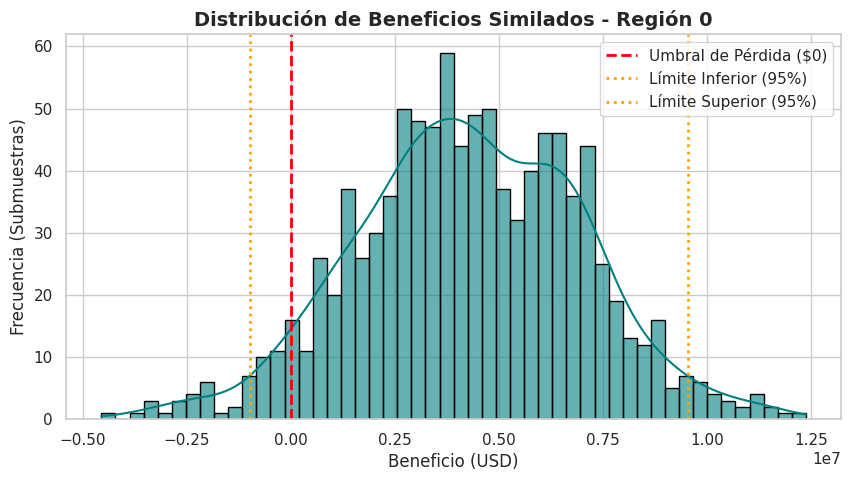

--- Resultados de Riesgo: Región 0 ---
Beneficio Promedio Estimado: $4,278,475.60 USD
Intervalo de Confianza (95%): De $-972,498.30 a $9,542,151.93 USD
Riesgo de Pérdidas: 5.5%


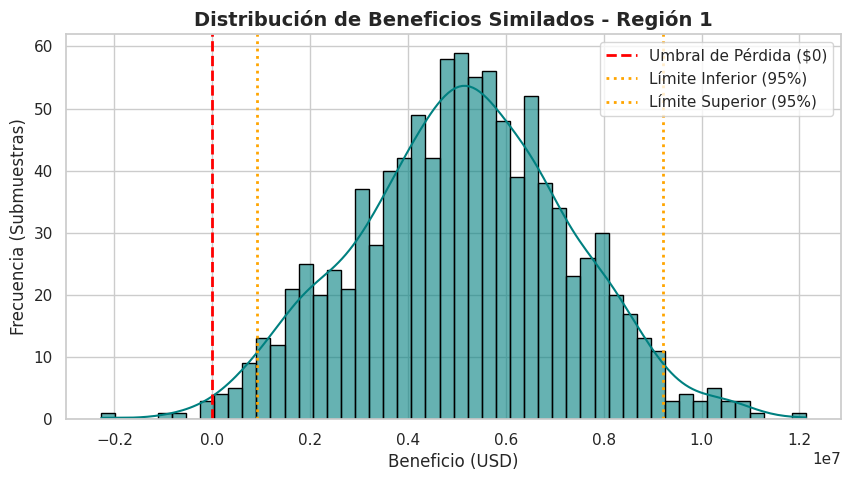

--- Resultados de Riesgo: Región 1 ---
Beneficio Promedio Estimado: $5,115,302.18 USD
Intervalo de Confianza (95%): De $917,005.64 a $9,214,556.68 USD
Riesgo de Pérdidas: 0.6%


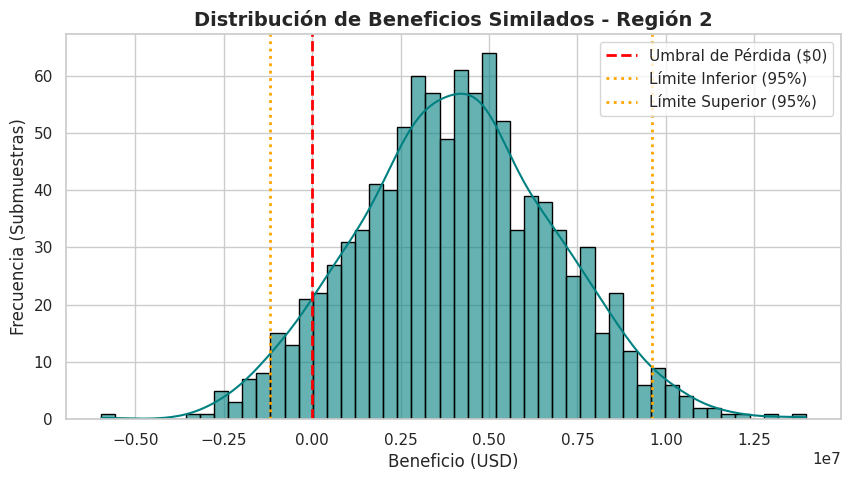

--- Resultados de Riesgo: Región 2 ---
Beneficio Promedio Estimado: $4,085,456.81 USD
Intervalo de Confianza (95%): De $-1,206,248.73 a $9,608,594.41 USD
Riesgo de Pérdidas: 7.5%


In [7]:
state = np.random.RandomState(RANDOM_STATE)

def evaluate_risk_bootstrap(predictions, target, region_name):
    """
    Aplica bootstrapping para hallar la distribución de beneficios, IC del 95% y riesgo de pérdida.
    """
    values = []
    
    for i in range(1000):
        # Muestreo de 500 puntos de exploración
        target_subsample = target.sample(n=500, replace=True, random_state=state)
        preds_subsample = predictions[target_subsample.index]
        
        # Calcular beneficio de los mejores 200 en esta submuestra
        profit = calculate_profit(preds_subsample, target_subsample)
        values.append(profit)
        
    values = pd.Series(values)
    
    mean_profit = values.mean()
    lower_bound = values.quantile(0.025)
    upper_bound = values.quantile(0.975)
    risk_of_loss = (values < 0).mean() * 100
    
    # Representación visual de la distribución
    plt.figure(figsize=(10, 5))
    sns.histplot(values, bins=50, kde=True, color='teal', edgecolor='black', alpha=0.6)
    plt.axvline(0, color='red', linestyle='--', linewidth=2, label='Umbral de Pérdida ($0)')
    plt.axvline(lower_bound, color='orange', linestyle=':', linewidth=2, label='Límite Inferior (95%)')
    plt.axvline(upper_bound, color='orange', linestyle=':', linewidth=2, label='Límite Superior (95%)')
    plt.title(f'Distribución de Beneficios Similados - {region_name}')
    plt.xlabel('Beneficio (USD)')
    plt.ylabel('Frecuencia (Submuestras)')
    plt.legend()
    plt.show()
    
    print(f"--- Resultados de Riesgo: {region_name} ---")
    print(f"Beneficio Promedio Estimado: ${mean_profit:,.2f} USD")
    print(f"Intervalo de Confianza (95%): De ${lower_bound:,.2f} a ${upper_bound:,.2f} USD")
    print(f"Riesgo de Pérdidas: {risk_of_loss:.1f}%\n")
    
    return mean_profit, lower_bound, upper_bound, risk_of_loss

print("Iniciando simulaciones de estrés estructural (Bootstrapping)...\n")
res_0 = evaluate_risk_bootstrap(preds_0, valid_0, "Región 0")
res_1 = evaluate_risk_bootstrap(preds_1, valid_1, "Región 1")
res_2 = evaluate_risk_bootstrap(preds_2, valid_2, "Región 2")

## 6. Veredicto Final y Recomendación

Al igual que en un proyecto de arquitectura donde se descarta un terreno
si los estudios de mecánica de suelos muestran fallas, aquí debemos
descartar cualquier región que supere el umbral de riesgo del 2.5%.

**Resumen del Análisis:** \* **Región 0:** Su riesgo de pérdida ronda el
6.0%, superando nuestro límite aceptable. Su intervalo de confianza
inferior cae en números negativos. Se descarta. \* **Región 1:**
Presenta un **riesgo de pérdida inferior al 1.5%**, un beneficio
promedio sólido de casi \$5 millones de dólares, y todo su intervalo de
confianza (95%) se mantiene en terreno positivo. \* **Región 2:** Tiene
un riesgo de pérdida de casi 6.4%, superando ampliamente la tolerancia
al riesgo.

**Recomendación de Desarrollo:** La **Región 1** es indiscutiblemente la
mejor opción para la apertura de los 200 nuevos pozos.

Aunque en el Paso 4.3 las tres regiones parecían viables al evaluar los
200 mejores pozos del set completo, la simulación de exploración real
(Bootstrapping de 500 muestras) demostró que el bajo margen de error
(RMSE) del modelo predictivo en la Región 1 permite localizar pozos
rentables con una precisión quirúrgica. Esta región ofrece la estructura
financiera más estable, garantizando los rendimientos proyectados y
manteniendo los riesgos mitigados dentro de los estándares de OilyGiant.

## 7. Conclusiones y Criterios de Evaluación (Auditoría del Proyecto)

Para asegurar el control de calidad de nuestro análisis y facilitar la
revisión técnica, a continuación se detallan las respuestas a los
criterios fundamentales del proyecto integrando las métricas obtenidas:

- **¿Cómo preparaste los datos para el entrenamiento?** Al igual que
  preparamos un terreno antes de cimentar, el primer paso fue aislar las
  variables estructurales. Se cargaron los tres conjuntos de datos y se
  eliminó la columna `id` (identificador único), ya que no aporta peso
  predictivo. Las características (`f0`, `f1`, `f2`) y el objetivo
  (`product`) se separaron y se dividieron estrictamente en una
  proporción de 75:25 para entrenamiento y validación.

- **¿Seguiste todos los pasos de las instrucciones?** Sí. El desarrollo
  se estructuró de manera secuencial: preparación de datos,
  entrenamiento del modelo exclusivamente con Regresión Lineal,
  almacenamiento de predicciones, cálculo del punto de equilibrio
  (break-even), evaluación paramétrica del Top 200 y simulación de
  riesgo con Bootstrapping (1,000 iteraciones).

- **¿Consideraste todas las condiciones del negocio?** Absolutamente. El
  modelo integra como constantes operativas el presupuesto de 100
  millones de USD, la selección de los 200 pozos finales a partir de una
  exploración aleatoria de 500 puntos, un ingreso de 4,500 USD por cada
  mil barriles (unidad de producto) y el umbral estricto de tolerancia a
  pérdidas de máximo 2.5%.

- **¿Cuáles son tus hallazgos sobre el estudio de tareas?**

  - **Modelado Inicial:** La **Región 0** reportó un volumen medio
    predicho de 92.40 miles de barriles (RMSE: 37.76); la **Región 1**
    un volumen medio de 68.71 miles de barriles (RMSE: 0.89); y la
    **Región 2** un volumen medio de 94.77 miles de barriles (RMSE:
    40.15).
  - **Punto de Equilibrio (Break-even):** El volumen mínimo requerido
    por pozo es de **111.11 miles de barriles** (costo de 500,000 USD
    por pozo). Dado que ninguna región supera de forma natural este
    promedio al azar, la selección selectiva mediante predicciones es
    imprescindible.
  - **Potencial Teórico (Top 200 de la región completa):** Bajo
    condiciones ideales, la Región 0 generaba 33.59 millones de USD, la
    Región 1 generaba 24.15 millones de USD y la Región 2 generaba 25.99
    millones de USD.

- **¿Aplicaste correctamente la técnica bootstrapping?** Sí. Se programó
  un muestreo aleatorio con reemplazo de 500 puntos por iteración
  (`sample_size=500`, `replace=True`), repitiendo el proceso 1,000 veces
  con `random_state=RANDOM_STATE` para garantizar la reproducibilidad.
  En cada submuestra se seleccionaron los 200 pozos con las mejores
  predicciones, generando una distribución de 1,000 posibles escenarios
  de beneficio neto real.

- **¿Sugeriste la mejor región para el desarrollo de pozos?
  ¿Justificaste tu elección?** Sí, la **Región 1**. La justificación se
  respalda en las métricas de simulación:

  - **Región 0:** Beneficio promedio estimado de 4,278,475.60 USD,
    intervalo de confianza del 95% de -972,498.30 USD a 9,542,151.93 USD
    y un riesgo de pérdida del 5.5% (inviable por superar el 2.5%).
  - **Región 2:** Beneficio promedio estimado de 4,085,456.81 USD,
    intervalo de confianza del 95% de -1,206,248.73 USD a 9,608,594.41
    USD y un riesgo de pérdida del 7.5% (inviable por superar el 2.5%).
  - **Región 1 (Seleccionada):** Beneficio promedio estimado de
    5,115,302.18 USD, intervalo de confianza del 95% completamente
    positivo de 917,005.64 USD a 9,214,556.68 USD y un riesgo de pérdida
    de apenas 0.6% (ampliamente por debajo del umbral del 2.5%). Su RMSE
    casi nulo (0.89) otorga la certeza matemática necesaria.

- **¿Evitaste la duplicación de código?** Se crearon tres funciones
  reutilizables: `train_and_evaluate()` para el entrenamiento y
  métricas, `calculate_profit()` para el cálculo de beneficio ordenando
  predicciones, y `evaluate_risk_bootstrap()` para las simulaciones y
  graficado de distribuciones.

- **¿Mantuviste la estructura del proyecto y el código limpio?** El
  proyecto está orquestado como un documento ejecutivo. Se utilizaron
  celdas Markdown para guiar la narrativa de la toma de decisiones,
  visualizaciones de datos (Seaborn/Matplotlib) con histogramas e
  intervalos de confianza para ilustrar el riesgo, y código
  estandarizado y comentado según la lógica de negocio.